# 📊 STEP 6 – Data Cleaning, Transformations & Enhanced EDA

## 🎯 Objective

The objective of this step is to prepare the Black Friday sales dataset for
advanced analysis by cleaning the data, handling missing values, validating
data quality, standardizing categorical variables, identifying outliers,
creating useful customer-level features, and performing Exploratory Data
Analysis (EDA).

This step will help us transform the raw transactional data into a
reliable and analysis-ready dataset and uncover important patterns in
customer purchasing behavior, product performance, and sales.

---

## 🔍 Key Activities

### 1️⃣ Data Cleaning
- Load and understand the dataset
- Validate data types
- Check missing values
- Check duplicate records
- Validate important business fields

### 2️⃣ Data Transformation
- Standardize Age groups
- Standardize City Tenure
- Create readable Marital Status labels
- Prepare categorical variables for analysis

### 3️⃣ Outlier Analysis
- Analyze the distribution of Purchase Amount
- Identify unusually high or low purchase values
- Decide whether potential outliers should be retained or treated

### 4️⃣ Feature Engineering
Create new customer-level metrics:

- 💰 **Customer Lifetime Value (CLV)**
- 🛍️ **Category Breadth**
- 🏙️ **City Loyalty Index**

### 5️⃣ Exploratory Data Analysis
Analyze:
- Purchase distribution
- Customer demographics
- Gender and age-group behavior
- City-level sales
- Product category performance
- Customer spending patterns
- Relationships between numerical variables

### 6️⃣ Visualization
Use:
- 📊 Bar Charts
- 📈 Histograms
- 📦 Boxplots
- 🔥 Correlation Heatmaps

---

## 🗂️ Step 6 Workflow

**Load Data → Validate → Clean → Transform → Analyze Outliers →  
Feature Engineering → Descriptive Statistics → EDA → Correlation Analysis →  
Business Insights**

---

## 📌 Expected Outcome

By the end of Step 6, we will have:

✅ A clean and analysis-ready dataset  
✅ Validated and standardized variables  
✅ Missing values appropriately handled  
✅ Potential outliers identified  
✅ Customer-level analytical features created  
✅ Descriptive statistics generated  
✅ Important patterns visualized  
✅ Initial business insights identified  

---

## 💡 Business Focus

The analysis will help answer questions such as:

- Which customer groups contribute the most sales?
- Which age groups show higher purchasing behavior?
- Which city categories generate more revenue?
- Which product categories perform best?
- Which customers can be considered high-value?
- How do customer characteristics relate to purchase behavior?

---

### 🚀 From Clean Data to Business Insights

> **Clean Data → Transform → Explore → Understand → Discover Insights**

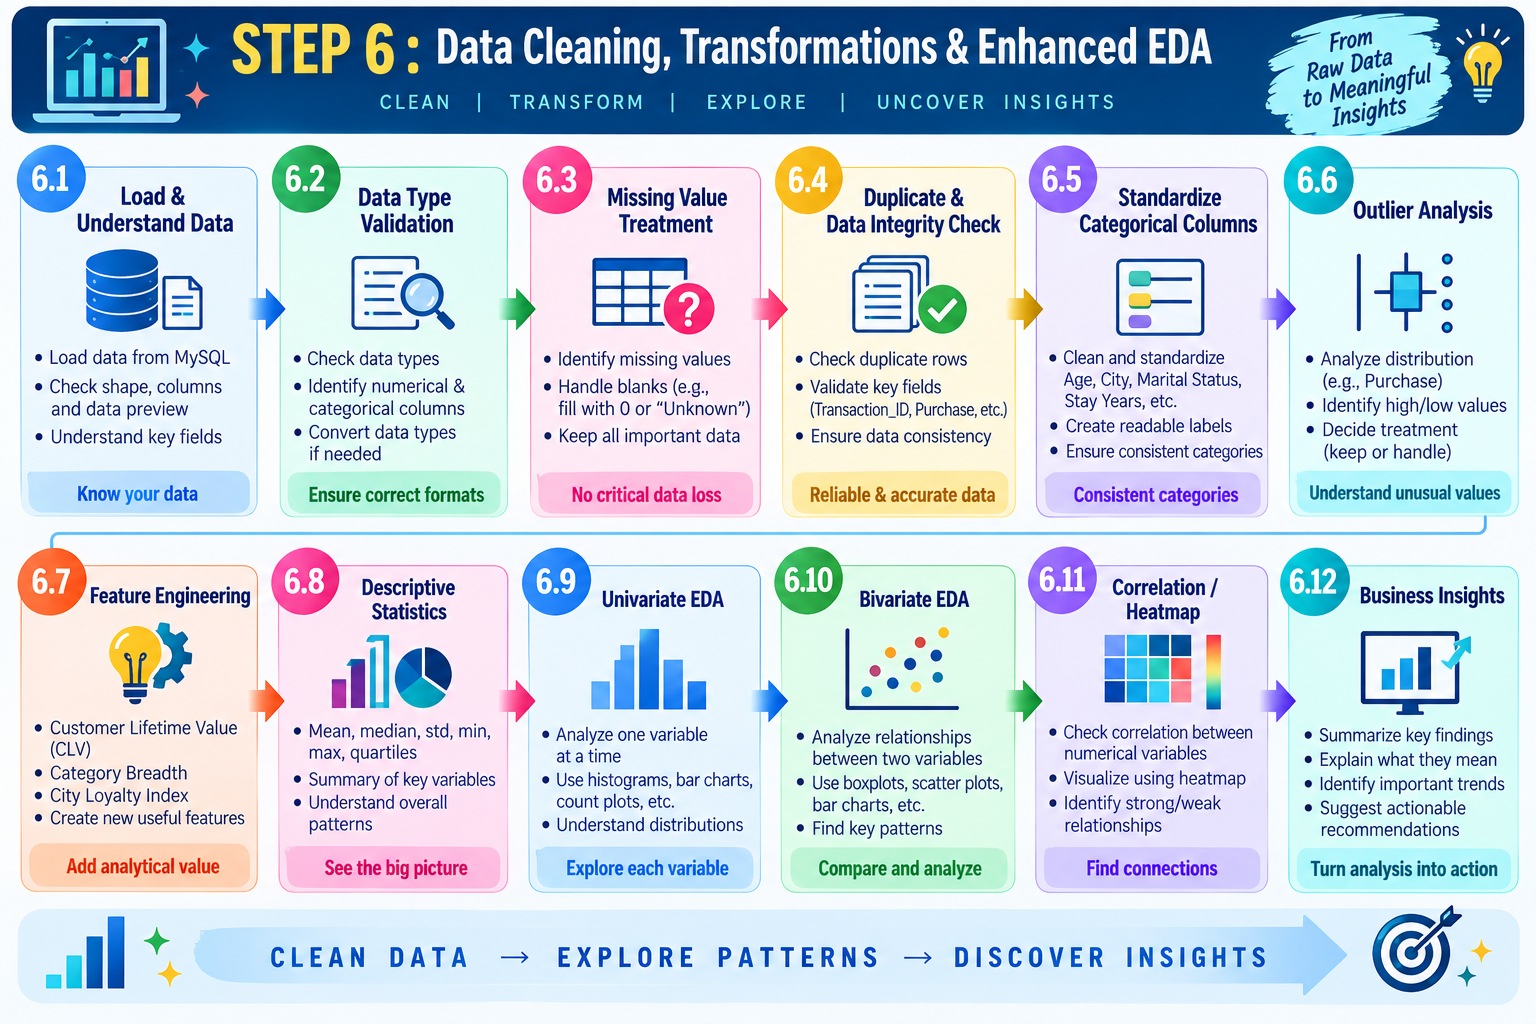

In [6]:
!pip install mysql-connector-python

In [10]:
import mysql.connector
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [8]:
# Replace placeholders with your local MySQL credentials before running

connection = mysql.connector.connect(
    host="******",
    user="******",
    password="******",
    database="black_friday_db"
)

In [12]:
sns.set_theme(style="whitegrid")

In [13]:
query = """
SELECT *
FROM black_friday_data;
"""

df_black_friday = pd.read_sql(query, connection)

print("Data loaded successfully!")

C:\Users\Megha Solanki\AppData\Local\Temp\ipykernel_10520\3738469544.py:6: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_black_friday = pd.read_sql(query, connection)


Data loaded successfully!


In [15]:
# Check the dataset

df_black_friday.head()

,Transaction_ID,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1,1000001,P00069042,F,0-17,10,A,2,0,3,,,8370
1,2,1000001,P00248942,F,0-17,10,A,2,0,1,6,14,15200
2,3,1000001,P00087842,F,0-17,10,A,2,0,12,,,1422
3,4,1000001,P00085442,F,0-17,10,A,2,0,12,14,,1057
4,5,1000002,P00285442,M,55+,16,C,4+,0,8,,,7969


In [16]:
# Understand the Dataset

df_black_friday.shape

(550068, 13)

In [17]:
df_black_friday.columns

Index(['Transaction_ID', 'User_ID', 'Product_ID', 'Gender', 'Age',
       'Occupation', 'City_Category', 'Stay_In_Current_City_Years',
       'Marital_Status', 'Product_Category_1', 'Product_Category_2',
       'Product_Category_3', 'Purchase'],
      dtype='object')

In [18]:
# Check Data Types

df_black_friday.dtypes

Transaction_ID                 int64
User_ID                        int64
Product_ID                    object
Gender                        object
Age                           object
Occupation                     int64
City_Category                 object
Stay_In_Current_City_Years    object
Marital_Status                 int64
Product_Category_1             int64
Product_Category_2            object
Product_Category_3            object
Purchase                       int64
dtype: object

In [19]:
# Check missing values

df_black_friday.isnull().sum()

Transaction_ID                0
User_ID                       0
Product_ID                    0
Gender                        0
Age                           0
Occupation                    0
City_Category                 0
Stay_In_Current_City_Years    0
Marital_Status                0
Product_Category_1            0
Product_Category_2            0
Product_Category_3            0
Purchase                      0
dtype: int64

In [20]:
df_black_friday["Product_Category_2"].value_counts(dropna=False).head(10)

Product_Category_2
      173638
8      64088
14     55108
2      49217
16     43255
15     37855
5      26235
4      25677
6      16466
11     14134
Name: count, dtype: int64

In [21]:
df_black_friday["Product_Category_3"].value_counts(dropna=False).head(10)

Product_Category_3
      383247
16     32636
15     28013
14     18428
17     16702
5      16658
8      12562
9      11579
12      9246
13      5459
Name: count, dtype: int64

## Missing Value Treatment

Product_Category_2 → 173,638 missing

Product_Category_3 → 383,247 missing

In [23]:
df_black_friday["Product_Category_2"] = (
    df_black_friday["Product_Category_2"].fillna(0)
)

df_black_friday["Product_Category_3"] = (
    df_black_friday["Product_Category_3"].fillna(0)
)

In [24]:
df_black_friday.isnull().sum()

Transaction_ID                0
User_ID                       0
Product_ID                    0
Gender                        0
Age                           0
Occupation                    0
City_Category                 0
Stay_In_Current_City_Years    0
Marital_Status                0
Product_Category_1            0
Product_Category_2            0
Product_Category_3            0
Purchase                      0
dtype: int64

### Missing Value Treatment

Product_Category_2 and Product_Category_3 contained missing values.
Instead of removing these transactions, missing category values were
represented as 0, indicating that no secondary or tertiary category
was recorded.

This approach preserves the complete transaction population.

## Duplicate Check

In [25]:
df_black_friday.duplicated().sum()

np.int64(0)

In [26]:
len(df_black_friday)

550068

## Check Important Business Fields

In [28]:
df_black_friday[
    ["User_ID", "Product_ID", "Purchase"]
].isnull().sum()

User_ID       0
Product_ID    0
Purchase      0
dtype: int64

In [29]:
df_black_friday["Purchase"].min()

12

In [34]:
df_black_friday["Purchase"].max()

23961

## Standardize Age

In [35]:
df_black_friday["Age"].value_counts()

Age
26-35    219587
36-45    110013
18-25     99660
46-50     45701
51-55     38501
55+       21504
0-17      15102
Name: count, dtype: int64

In [38]:
age_order= [
    "0-17",
    "18-25",
    "23-35",
    "36-45",
    "46-50",
    "51-55",
    "55+"
]

df_black_friday["Age"] = pd.Categorical(
    df_black_friday["Age"],
    categories = age_order,
    ordered = True
)

In [39]:
df_black_friday["Age"].value_counts().sort_index()

Age
0-17      15102
18-25     99660
23-35         0
36-45    110013
46-50     45701
51-55     38501
55+       21504
Name: count, dtype: int64

## Standardize City Tenure

In [41]:
df_black_friday["Stay_In_Current_City_Years"].value_counts()

Stay_In_Current_City_Years
1     193821
2     101838
3      95285
4+     84726
0      74398
Name: count, dtype: int64

In [43]:
df_black_friday["Stay_Years"] = (
    df_black_friday["Stay_In_Current_City_Years"]
    .replace("4+", 4)
    .astype(int)
)

In [44]:
df_black_friday["Stay_Years"].value_counts().sort_index()

Stay_Years
0     74398
1    193821
2    101838
3     95285
4     84726
Name: count, dtype: int64

## Check Gender, City & Marital Status

In [45]:
df_black_friday["Gender"].value_counts()

Gender
M    414259
F    135809
Name: count, dtype: int64

In [46]:
df_black_friday["City_Category"].value_counts()

City_Category
B    231173
C    171175
A    147720
Name: count, dtype: int64

In [47]:
df_black_friday["Marital_Status"].value_counts()

Marital_Status
0    324731
1    225337
Name: count, dtype: int64

In [48]:
df_black_friday["Marital_Status_Label"] = (
    df_black_friday["Marital_Status"]
    .map({
        0: "Single",
        1: "Married"
    })
)

In [49]:
df_black_friday["Marital_Status_Label"].value_counts()

Marital_Status_Label
Single     324731
Married    225337
Name: count, dtype: int64

## Outlier Analysis

In [51]:
df_black_friday["Purchase"].describe()

count    550068.000000
mean       9263.968713
std        5023.065394
min          12.000000
25%        5823.000000
50%        8047.000000
75%       12054.000000
max       23961.000000
Name: Purchase, dtype: float64

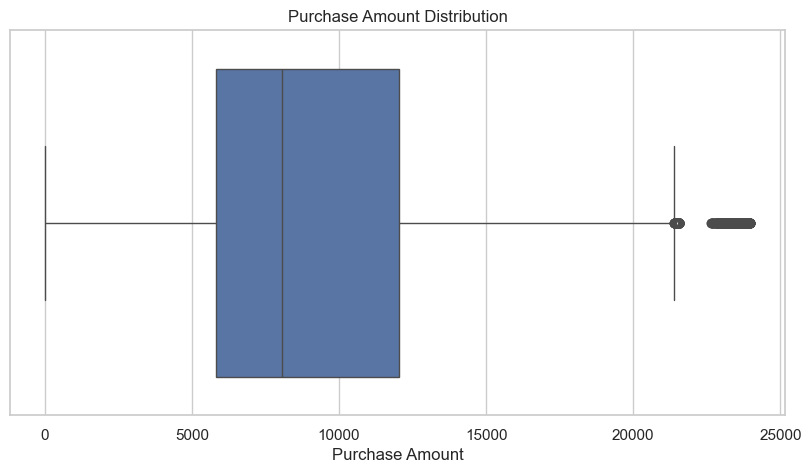

In [52]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df_black_friday["Purchase"])

plt.title("Purchase Amount Distribution")
plt.xlabel("Purchase Amount")

plt.show()

## Descriptive Statistics

In [54]:
df_black_friday.describe()

,Transaction_ID,User_ID,Occupation,Marital_Status,Product_Category_1,Purchase,Stay_Years
count,550068.000000,5.500680e+05,550068.000000,550068.000000,550068.000000,550068.000000,550068.000000
mean,275034.500000,1.003029e+06,8.076707,0.409653,5.404270,9263.968713,1.858418
std,158791.098273,1.727592e+03,6.522660,0.491770,3.936211,5023.065394,1.289443
min,1.000000,1.000001e+06,0.000000,0.000000,1.000000,12.000000,0.000000
25%,137517.750000,1.001516e+06,2.000000,0.000000,1.000000,5823.000000,1.000000
50%,275034.500000,1.003077e+06,7.000000,0.000000,5.000000,8047.000000,2.000000
75%,412551.250000,1.004478e+06,14.000000,1.000000,8.000000,12054.000000,3.000000
max,550068.000000,1.006040e+06,20.000000,1.000000,20.000000,23961.000000,4.000000


In [55]:
df_black_friday["Purchase"].describe()

count    550068.000000
mean       9263.968713
std        5023.065394
min          12.000000
25%        5823.000000
50%        8047.000000
75%       12054.000000
max       23961.000000
Name: Purchase, dtype: float64

### Descriptive Statistics – Purchase

The Purchase variable was analyzed using descriptive statistics to
understand the central tendency and spread of transaction values.

The mean represents the average transaction value, while the median
represents the middle transaction value. The standard deviation
indicates the variability in customer spending.

The difference between the maximum value and the upper quartile was
also reviewed to identify potential high-value transactions.

## FEATURE ENGINEERING ⭐

#### Customer Lifetime Value

- CLV = Total Purchase per User / Number of Transactions

In [59]:
customer_summary = (
    df_black_friday
    .groupby("User_ID")
    .agg(
        Total_Purchase=("Purchase", "sum"),
        Transaction_Count=("Transaction_ID", "count")
    )
    .reset_index()
)

In [60]:
customer_summary.head()

,User_ID,Total_Purchase,Transaction_Count
0,1000001,334093,35
1,1000002,810472,77
2,1000003,341635,29
3,1000004,206468,14
4,1000005,821001,106


## Category Breadth

### Category Breadth = distinct product categories purchased per customer.

In [64]:
category_columns = [
    "Product_Category_1",
    "Product_Category_2",
    "Product_Category_3"
]

In [66]:
df_black_friday["Category_Breadth"] = (
    df_black_friday[category_columns]
    .replace(0, np.nan)
    .nunique(axis=1)
)

In [67]:
category_long = df_black_friday[
    ["User_ID",
     "Product_Category_1",
     "Product_Category_2",
     "Product_Category_3"]
].melt(
    id_vars="User_ID",
    value_name="Product_Category"
)

In [68]:
category_long = category_long[
    category_long["Product_Category"] != 0
]

In [69]:
customer_breadth = (
    category_long
    .groupby("User_ID")["Product_Category"]
    .nunique()
    .reset_index(name="Category_Breadth")
)

In [70]:
customer_breadth.head()

,User_ID,Category_Breadth
0,1000001,23
1,1000002,20
2,1000003,16
3,1000004,12
4,1000005,27


## City Loyalty Index

- City Loyalty Index = Average Purchase × Stay Years

In [71]:
customer_city = (
    df_black_friday
    .groupby("User_ID")
    .agg(
        Avg_Purchase=("Purchase", "mean"),
        Stay_Years=("Stay_Years", "first")
    )
    .reset_index()
)

In [72]:
customer_city["City_Loyalty_Index"] = (
    customer_city["Avg_Purchase"] *
    customer_city["Stay_Years"]
)

In [73]:
customer_city.head()

,User_ID,Avg_Purchase,Stay_Years,City_Loyalty_Index
0,1000001,9545.514286,2,19091.028571
1,1000002,10525.610390,4,42102.441558
2,1000003,11780.517241,3,35341.551724
3,1000004,14747.714286,2,29495.428571
4,1000005,7745.292453,1,7745.292453


## Final Customer Analysis Table

In [75]:
customer_analysis = customer_summary.merge(
    customer_breadth,
    on="User_ID",
    how="left"
)

In [76]:
customer_analysis = customer_analysis.merge(
    customer_city,
    on="User_ID",
    how="left"
)

In [77]:
customer_analysis.head()

,User_ID,Total_Purchase,Transaction_Count,Category_Breadth,Avg_Purchase,Stay_Years,City_Loyalty_Index
0,1000001,334093,35,23,9545.514286,2,19091.028571
1,1000002,810472,77,20,10525.610390,4,42102.441558
2,1000003,341635,29,16,11780.517241,3,35341.551724
3,1000004,206468,14,12,14747.714286,2,29495.428571
4,1000005,821001,106,27,7745.292453,1,7745.292453


## EDA 1: Purchase Distribution

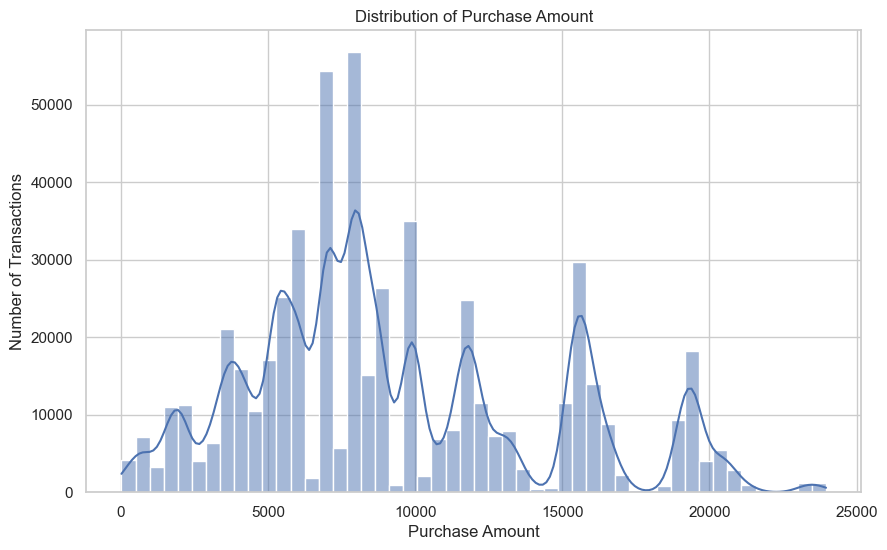

In [78]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df_black_friday["Purchase"],
    bins=50,
    kde=True
)

plt.title("Distribution of Purchase Amount")
plt.xlabel("Purchase Amount")
plt.ylabel("Number of Transactions")

plt.show()

### Business question

- Is customer spending normally distributed or skewed?
- The purchase amount data is right-skewed and multimodal; it is not normally distributed.

### Analytical Breakdown

Multimodal Clusters (Pricing Tiers): Spending clusters around distinct price bands—most notably at ~$7,000–$8,000, ~$10,000, ~$15,000, and ~$19,000. Customer transactions do not vary continuously around a single average; instead, spending is driven by specific product category pricing thresholds.

Positive (Right) Skew: The vast majority of transaction volume is concentrated under $10,000, while a long right tail extends past $20,000. Higher-value purchases are fewer in number but stretch the upper bound of revenue.

Non-Bell Shape: The data violates all parameters of a normal distribution (lack of symmetry, presence of multiple modes, heavy right-hand tail).

### Strategic & Business Recommendations

Metric Selection: Do not rely on Mean (Average) Purchase Value as a primary KPI—the right skew will artificially inflate it. Use Median and Mode to track baseline customer behavior accurately.

Customer Segmentation Strategy: Treat the multiple peaks as distinct purchasing tiers (Budget, Core Mid-Tier, and High-Value/Premium). Tailor promotional strategies, bundling, and upsell campaigns to move buyers between these specific tiers rather than targeting a generic "average buyer."

Inventory & Margin Planning: Higher transaction volume at specific price clusters indicates high velocity for core pricing tiers. Ensure inventory alignment and optimize margins around these high-volume price points.

## EDA 2: Sales by Gender

In [80]:
gender_sales = (
    df_black_friday
    .groupby("Gender")["Purchase"]
    .sum()
    .sort_values(ascending=False)
)

gender_sales

Gender
M    3909580100
F    1186232642
Name: Purchase, dtype: int64

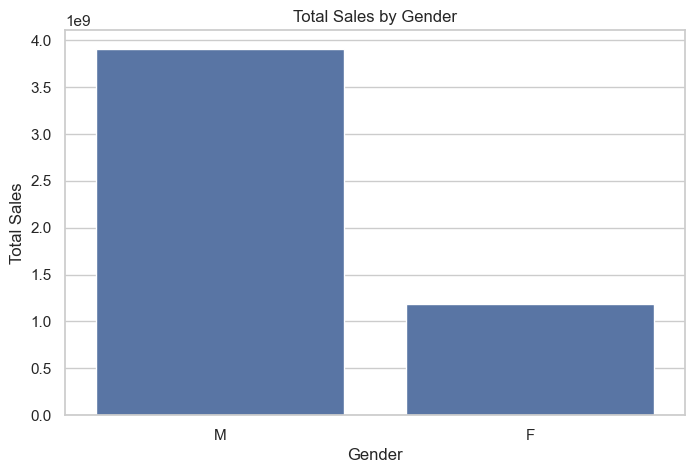

In [81]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=gender_sales.index,
    y=gender_sales.values
)

plt.title("Total Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")

plt.show()

## EDA 3: Sales by Age Group

In [83]:
age_sales = (
    df_black_friday
    .groupby("Age", observed=False)["Purchase"]
    .sum()
)

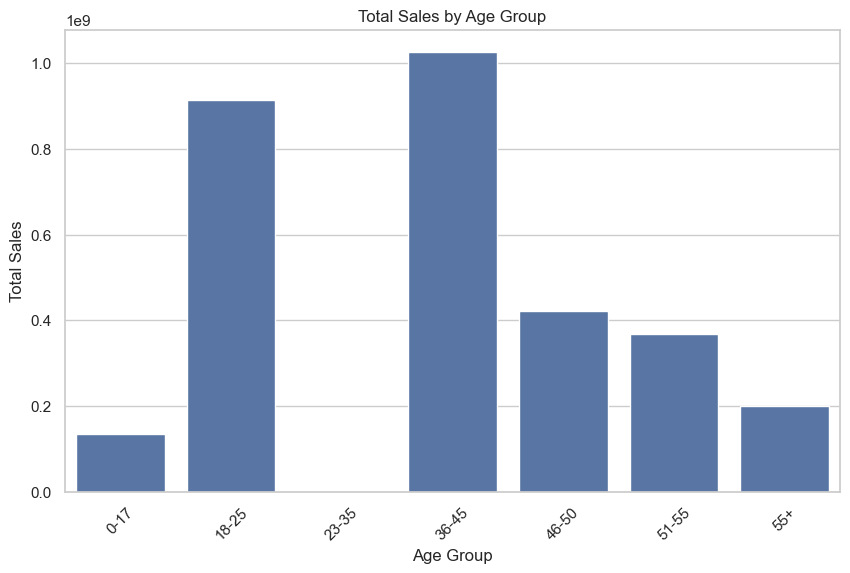

In [84]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=age_sales.index,
    y=age_sales.values
)

plt.title("Total Sales by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)

plt.show()

## EDA 5: Sales by City

In [85]:
city_sales = (
    df_black_friday
    .groupby("City_Category")["Purchase"]
    .sum()
    .sort_values(ascending=False)
)

city_sales

City_Category
B    2115533605
C    1663807476
A    1316471661
Name: Purchase, dtype: int64

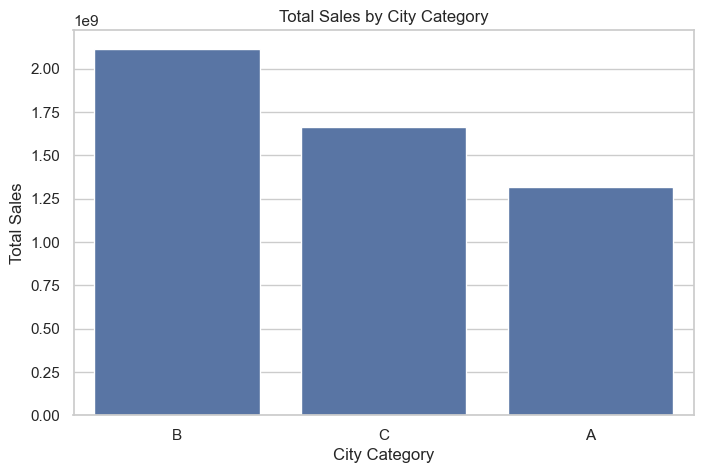

In [86]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=city_sales.index,
    y=city_sales.values
)

plt.title("Total Sales by City Category")
plt.xlabel("City Category")
plt.ylabel("Total Sales")

plt.show()

## EDA 6: Purchase by Marital Status

In [87]:
marital_purchase = (
    df_black_friday
    .groupby("Marital_Status_Label")["Purchase"]
    .mean()
)

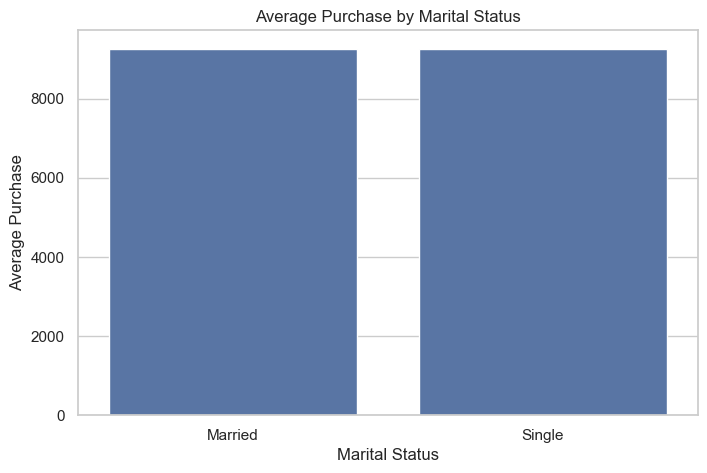

In [88]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=marital_purchase.index,
    y=marital_purchase.values
)

plt.title("Average Purchase by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Average Purchase")

plt.show()

## EDA 7: Product Category Performance

In [90]:
### For Product Category 1:

category_sales = (
    df_black_friday
    .groupby("Product_Category_1")["Purchase"]
    .sum()
    .sort_values(ascending=False)
)

In [91]:
category_sales.head(10)

Product_Category_1
1     1910013754
5      941835229
8      854318799
6      324150302
2      268516186
3      204084713
16     145120612
11     113791115
10     100837301
15      92969042
Name: Purchase, dtype: int64

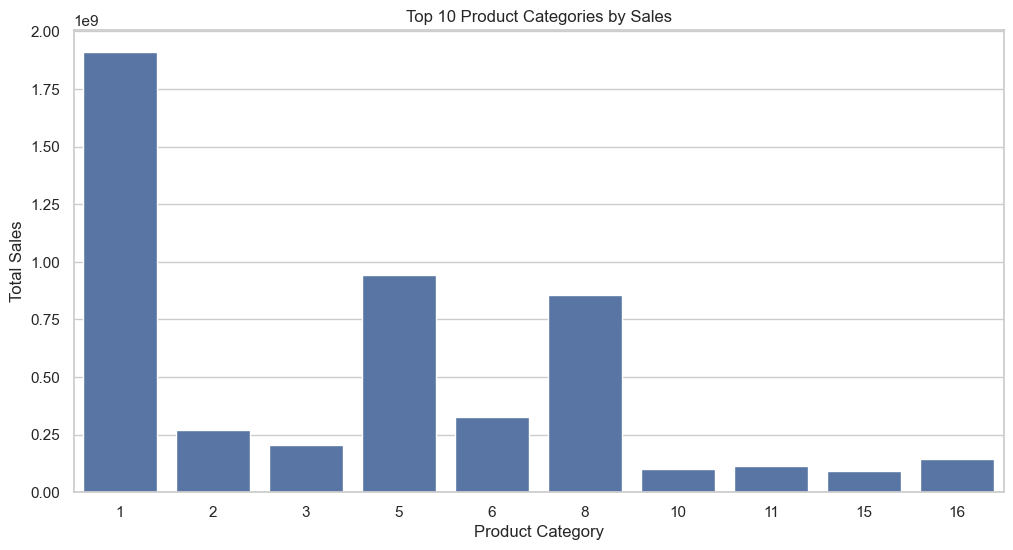

In [92]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_sales.head(10).index,
    y=category_sales.head(10).values
)

plt.title("Top 10 Product Categories by Sales")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")

plt.show()

## EDA 8: Boxplot by Age

### To identify:

- median spending
- variation
- high-value transactions
- potential outliers

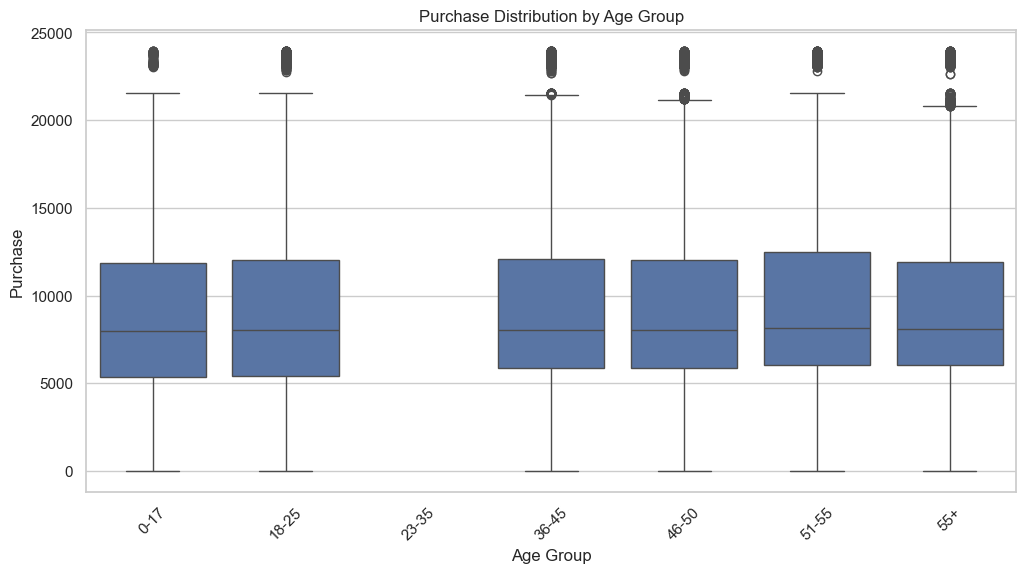

In [94]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_black_friday,
    x="Age",
    y="Purchase"
)

plt.title("Purchase Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Purchase")

plt.xticks(rotation=45)

plt.show()

## EDA 9: Boxplot by City

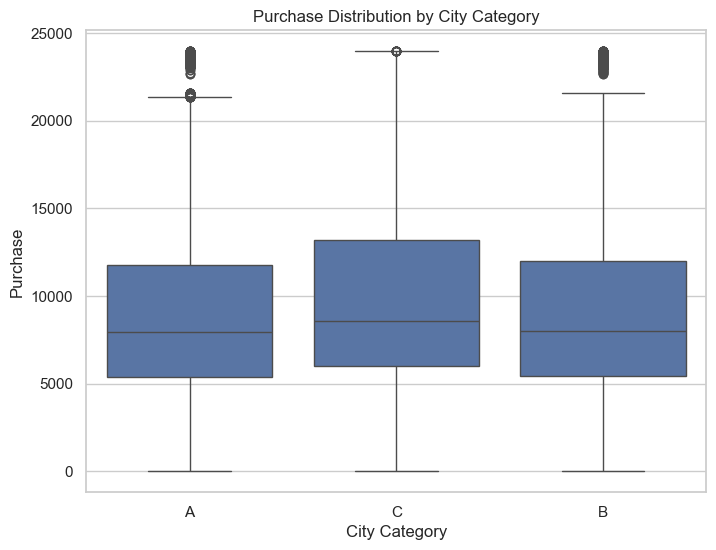

In [95]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df_black_friday,
    x="City_Category",
    y="Purchase"
)

plt.title("Purchase Distribution by City Category")
plt.xlabel("City Category")
plt.ylabel("Purchase")

plt.show()

## EDA 10: Correlation Heatmap

In [101]:
# Convert empty strings to NaN and coerce invalid values to numeric
for col in numeric_columns:
    # If the column contains string values like '4+', strip non-numeric characters first if needed:
    # df_black_friday[col] = df_black_friday[col].astype(str).str.replace('+', '', regex=False)

    df_black_friday[col] = pd.to_numeric(df_black_friday[col], errors='coerce')

# Calculate correlation
correlation_matrix = df_black_friday[numeric_columns].corr()

In [102]:
numeric_columns = [
    "Purchase",
    "Occupation",
    "Marital_Status",
    "Product_Category_1",
    "Product_Category_2",
    "Product_Category_3",
    "Stay_Years"
]

In [103]:
correlation_matrix = (
    df_black_friday[numeric_columns]
    .corr()
)

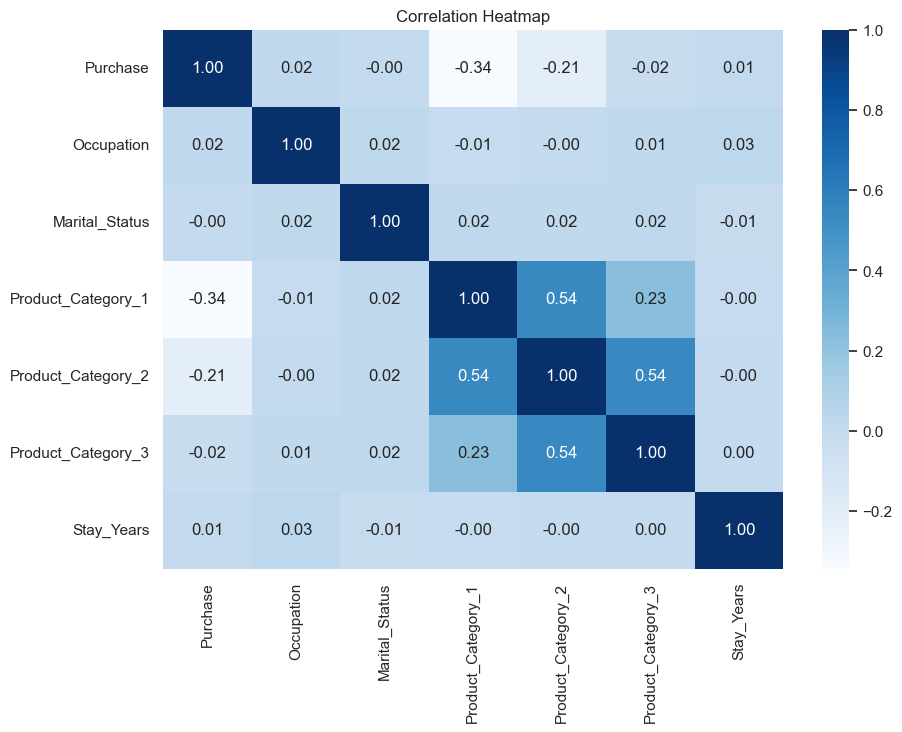

In [104]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues"
)

plt.title("Correlation Heatmap")

plt.show()

### Important point

 "The correlation indicates the strength and direction of association between the variables. Correlation does not establish causation."

## EDA 11: Top Customers

In [107]:
top_customers = (
    customer_analysis
    .sort_values("Total_Purchase", ascending=False)
    .head(10)
)

top_customers

,User_ID,Total_Purchase,Transaction_Count,Category_Breadth,Avg_Purchase,Stay_Years,City_Loyalty_Index
4166,1004277,10536909,979,37,10762.930541,0,0.000000
1634,1001680,8699596,1026,36,8479.138402,3,25437.415205
2831,1002909,7577756,718,36,10553.977716,1,10553.977716
1885,1001941,6817493,898,34,7591.863029,1,7591.863029
416,1000424,6573609,694,35,9472.059078,3,28416.177233
4335,1004448,6566245,575,34,11419.556522,0,0.000000
5683,1005831,6512433,727,35,8957.954608,2,17915.909216
981,1001015,6511314,740,36,8799.072973,4,35196.291892
3297,1003391,6477160,698,35,9279.598854,0,0.000000
1142,1001181,6387961,862,37,7410.627610,3,22231.882831


## EDA 12: Customer Segmentation

In [110]:
customer_analysis['CLV'] = customer_analysis['Total_Purchase']

customer_analysis['CLV'].describe()

count    5.891000e+03
mean     8.650166e+05
std      9.436445e+05
min      4.668100e+04
25%      2.376780e+05
50%      5.212130e+05
75%      1.119250e+06
max      1.053691e+07
Name: CLV, dtype: float64

In [112]:
customer_analysis["Customer_Segment"] = pd.qcut(
    customer_analysis["CLV"],
    q=4,
    labels=[
        "Low Value",
        "Medium-Low Value",
        "Medium-High Value",
        "High Value"
    ]
)

In [113]:
customer_analysis["Customer_Segment"].value_counts()

Customer_Segment
Low Value            1473
Medium-Low Value     1473
High Value           1473
Medium-High Value    1472
Name: count, dtype: int64

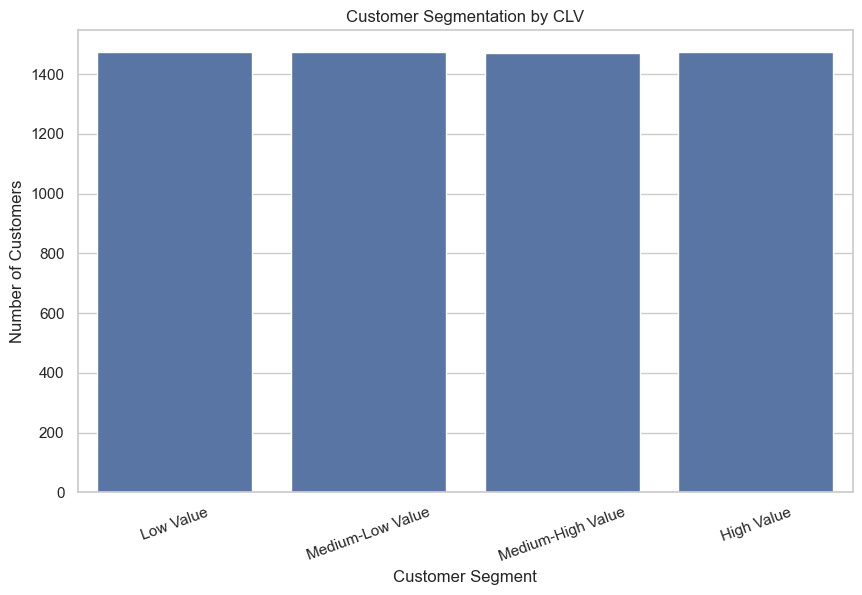

In [114]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=customer_analysis,
    x="Customer_Segment"
)

plt.title("Customer Segmentation by CLV")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20)

plt.show()

## EDA Summary Table

In [116]:
eda_summary = pd.DataFrame({
    "Metric": [
        "Total Transactions",
        "Unique Customers",
        "Unique Products",
        "Total Sales",
        "Average Purchase",
        "Median Purchase"
    ],
    "Value": [
        len(df_black_friday),
        df_black_friday["User_ID"].nunique(),
        df_black_friday["Product_ID"].nunique(),
        df_black_friday["Purchase"].sum(),
        df_black_friday["Purchase"].mean(),
        df_black_friday["Purchase"].median()
    ]
})

eda_summary

,Metric,Value
0,Total Transactions,5.500680e+05
1,Unique Customers,5.891000e+03
2,Unique Products,3.631000e+03
3,Total Sales,5.095813e+09
4,Average Purchase,9.263969e+03
5,Median Purchase,8.047000e+03


## Final Validation

In [118]:
print("Rows:", df_black_friday.shape[0])
print("Columns:", df_black_friday.shape[1])
print("Customers:", df_black_friday["User_ID"].nunique())
print("Products:", df_black_friday["Product_ID"].nunique())
print("Total Sales:", df_black_friday["Purchase"].sum())
print("Average Purchase:", df_black_friday["Purchase"].mean())
print("Missing Values:", df_black_friday.isnull().sum().sum())
print("Duplicate Rows:", df_black_friday.duplicated().sum())

Rows: 550068
Columns: 16
Customers: 5891
Products: 3631
Total Sales: 5095812742
Average Purchase: 9263.968712959126
Missing Values: 776472
Duplicate Rows: 0


## 💡 Business Suggestions

1. Target high-value customers
Identify customers with high spending and CLV and offer personalized promotions, loyalty benefits, and exclusive offers.

2. Focus on high-performing product categories
Maintain sufficient inventory for top-selling categories and explore cross-selling opportunities with related products.

3. Develop city-specific strategies
Allocate marketing budgets and inventory based on purchasing patterns across City Categories A, B, and C.

4. Improve customer retention
Use customer behavior and category breadth to identify loyal and high-potential customers and design retention campaigns.

5. Use data for future Black Friday planning
Use spending patterns, customer segments, and product demand to improve inventory planning, promotions, and resource allocation for future sales events.

## Business takeaway:

Use customer and product insights to target the right customers, stock the right products, and invest in the right markets.